# Does an autism connectivity classifier survive a new scanner?

Course analysis of the public ABIDE I preprocessed release. The model is fit in `src/abide_study.py`. This notebook reads the saved tables and figures.

## Question

If a connectivity model is trained on every site except one, does it still separate autism from control at the held-out site?

Age and sex, pooled cross-validation, and one label shuffle are the controls. Sites with fewer than 15 scans are shown and left out of the average. The result is a research finding about transfer. It is not a diagnostic test.


In [1]:
from pathlib import Path
import json
import pandas as pd

root = Path("..").resolve()
summary = json.loads((root / "results" / "summary.json").read_text())
sites = pd.read_csv(root / "results" / "per_site.csv")
print(f"{summary['n_subjects']} subjects, {summary['n_autism']} autism, {summary['n_control']} control, {summary['n_sites']} site labels")
print(f"leave-one-site-out balanced accuracy {summary['connectivity_loso_macro_balanced_accuracy']:.3f}")
print(f"leave-one-site-out AUROC            {summary['connectivity_loso_macro_auroc']:.3f}")
print(f"age and sex balanced accuracy       {summary['age_sex_loso_macro_balanced_accuracy']:.3f}")
print(f"pooled CV balanced accuracy         {summary['pooled_cv_balanced_accuracy_mean']:.3f}")
print(f"shuffled pooled AUROC               {summary['shuffled_pooled_cv_auroc_mean']:.3f}")
print(f"site-classifier accuracy            {summary['site_classifier_accuracy']:.3f}")
print(f"majority-site baseline              {summary['site_majority_baseline_accuracy']:.3f}")

856 subjects, 398 autism, 458 control, 20 site labels
leave-one-site-out balanced accuracy 0.674
leave-one-site-out AUROC            0.738
age and sex balanced accuracy       0.516
pooled CV balanced accuracy         0.658
shuffled pooled AUROC               0.515
site-classifier accuracy            0.680
majority-site baseline              0.199


## Cohort

NYU is large. Caltech and CMU are too small for the unweighted mean. Autism and control counts differ by site, which is why the headline metric is balanced accuracy rather than raw accuracy.

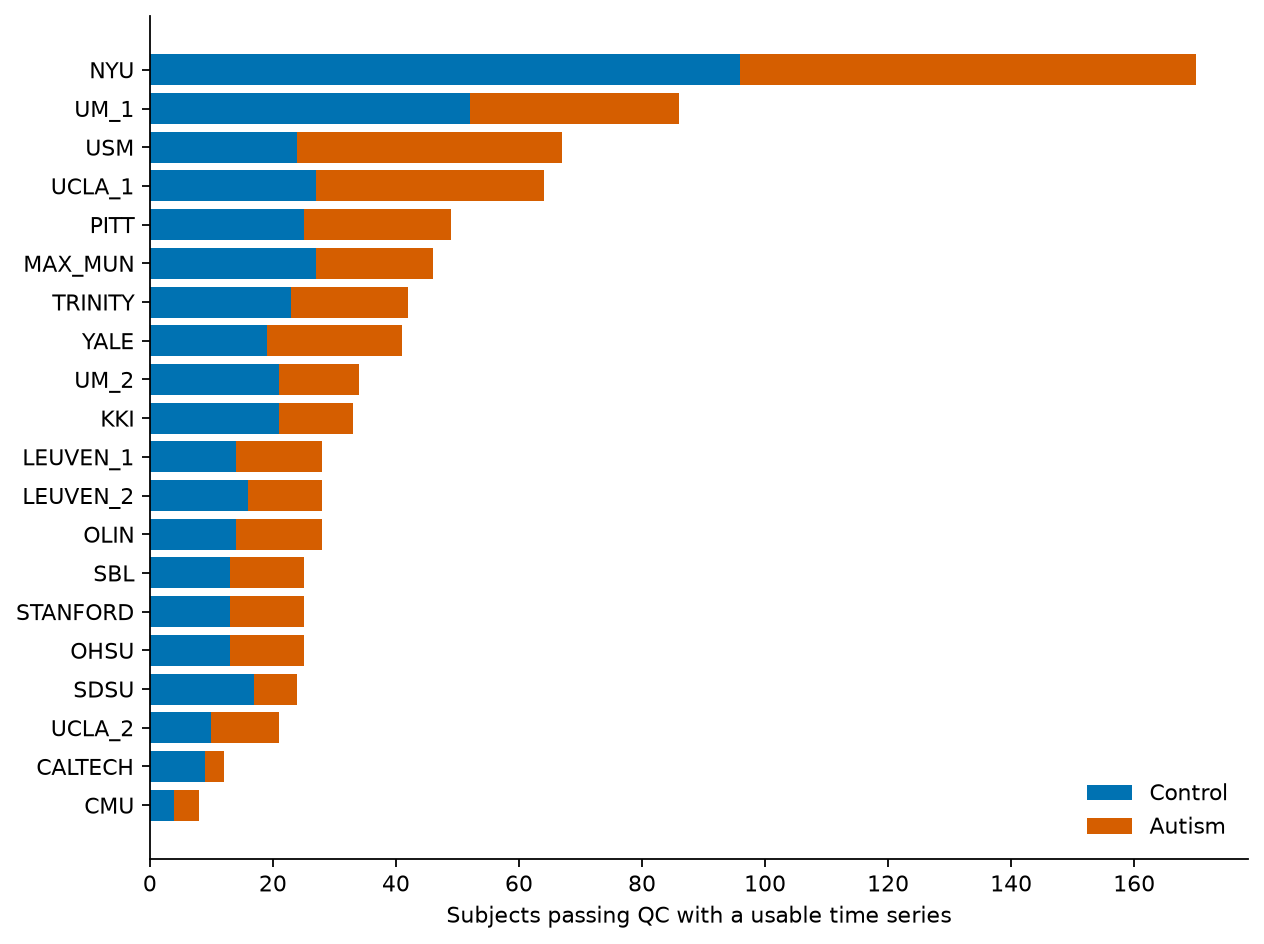

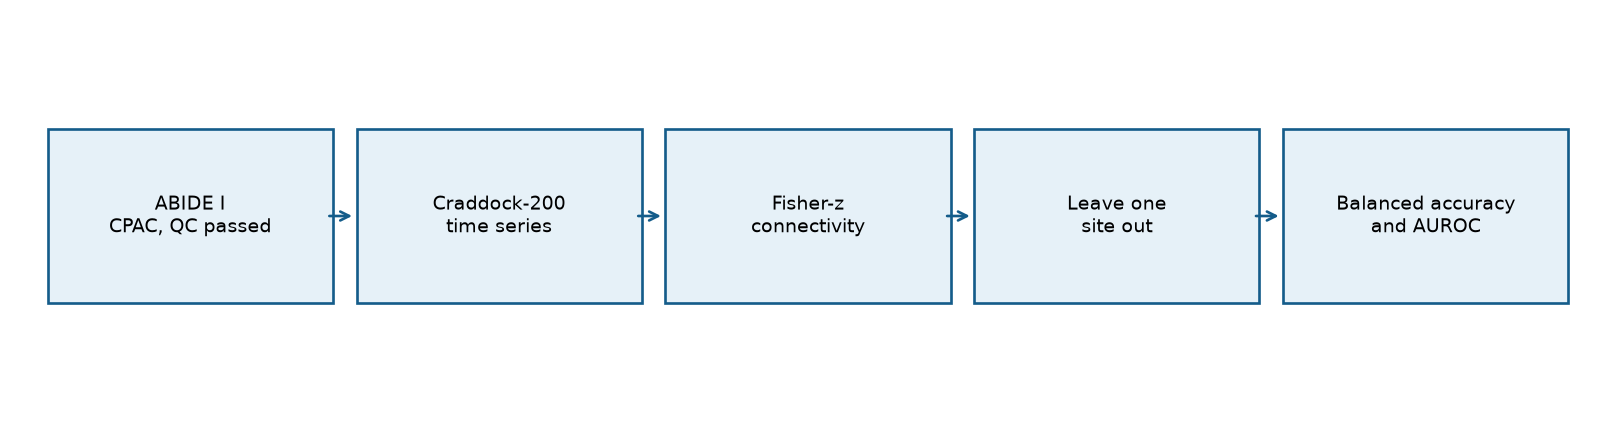

In [2]:
from IPython.display import Image, display
display(Image(filename=str(root / "report" / "figures" / "cohort_by_site.png")))
display(Image(filename=str(root / "report" / "figures" / "workflow.png")))

## What transferred, and where it did not

Leave-one-site-out and pooled cross-validation land in the same place, near 0.67 balanced accuracy. Age and sex do not. The site chart is the result that the average hides: MaxMun, OHSU, Stanford, and SBL are near chance, while USM is high on a larger sample.

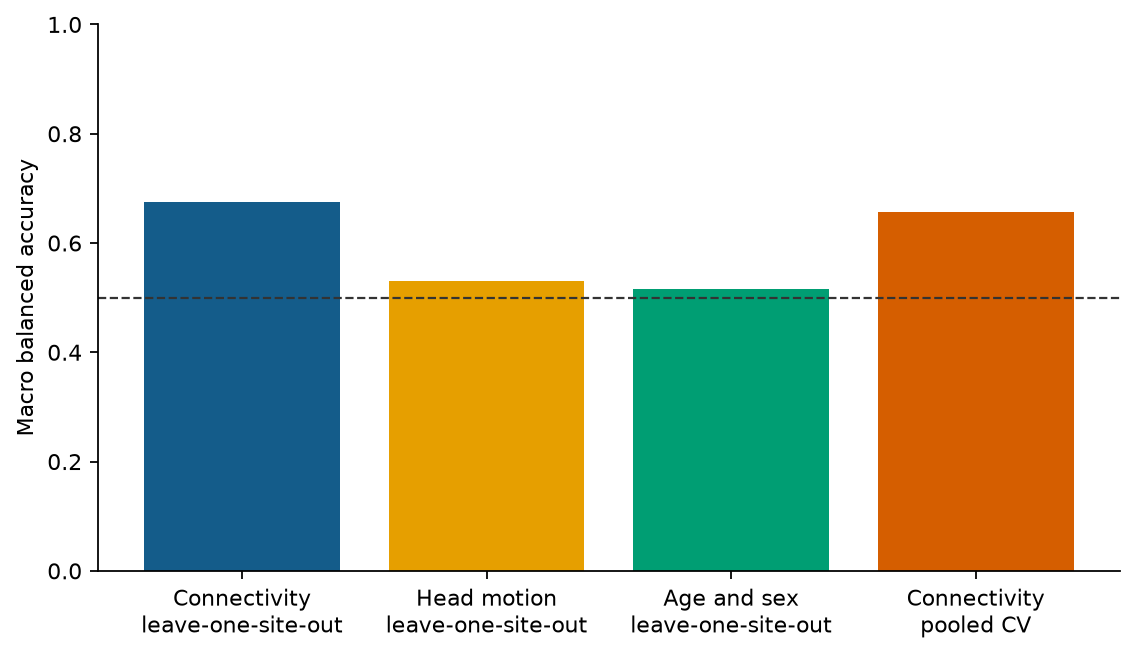

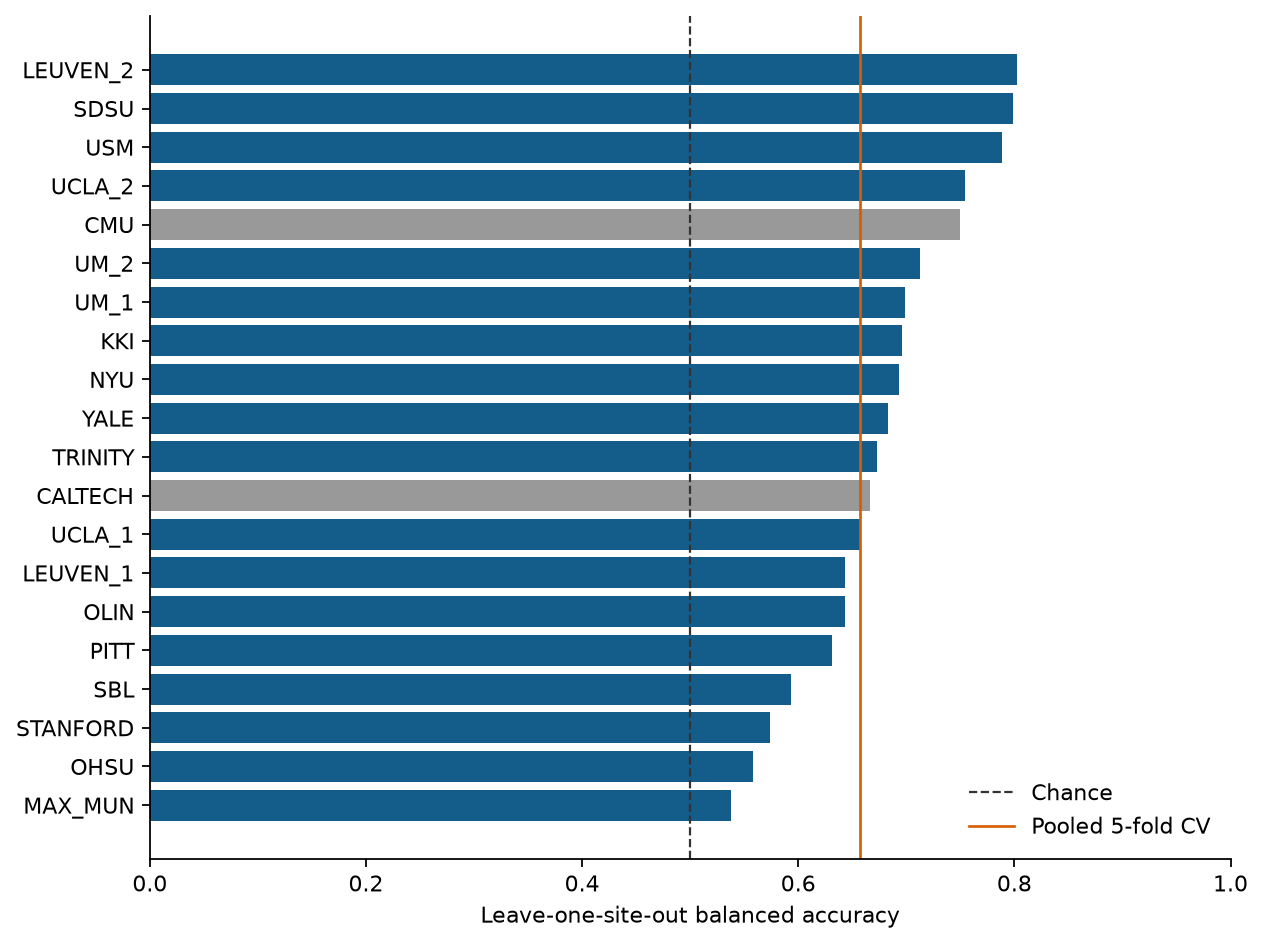

,site,n,n_autism,n_control,prevalence,small_site,connectivity_balanced_accuracy,connectivity_auroc,connectivity_auprc,connectivity_brier,age_sex_balanced_accuracy,age_sex_auroc,age_sex_auprc,age_sex_brier
0,NYU,170,74,96,0.435,False,0.693,0.778,0.761,0.194,0.526323,0.498733,0.441499,0.245844
1,UM_1,86,34,52,0.395,False,0.699,0.770,0.654,0.198,0.545814,0.522059,0.396469,0.244695
2,USM,67,43,24,0.642,False,0.789,0.819,0.864,0.179,0.483043,0.406008,0.569364,0.250795
3,UCLA_1,64,37,27,0.578,False,0.658,0.729,0.789,0.225,0.474474,0.470971,0.595497,0.255160
4,PITT,49,24,25,0.490,False,0.631,0.660,0.752,0.243,0.517500,0.496667,0.521879,0.249995
5,MAX_MUN,46,19,27,0.413,False,0.538,0.558,0.433,0.290,0.439571,0.467836,0.495094,0.260600
6,TRINITY,42,19,23,0.452,False,0.673,0.712,0.661,0.224,0.500000,0.510297,0.470103,0.252177
7,YALE,41,22,19,0.537,False,0.683,0.780,0.839,0.192,0.528708,0.503589,0.609734,0.253813
8,UM_2,34,13,21,0.382,False,0.712,0.773,0.714,0.189,0.485348,0.307692,0.299690,0.255896
9,KKI,33,12,21,0.364,False,0.696,0.813,0.721,0.229,0.517857,0.601190,0.465778,0.247049


In [3]:
display(Image(filename=str(root / "report" / "figures" / "model_comparison.png")))
display(Image(filename=str(root / "report" / "figures" / "loso_balanced_accuracy.png")))
show = sites.copy()
for col in ["prevalence", "connectivity_balanced_accuracy", "connectivity_auroc", "connectivity_auprc", "connectivity_brier"]:
    show[col] = show[col].map(lambda v: round(float(v), 3))
show = show.sort_values("n", ascending=False)
show

## How to read it

The same edges name the acquisition site far above the NYU base rate, so the representation still carries scanner and protocol. Leave-one-site-out cannot succeed just by recognizing a site it has never seen. The pooled Brier score is only a little better than predicting the autism rate. A threshold that is acceptable at one hospital can be wrong at the next.

Rerun the models from the repository root with `python src/abide_study.py`. The first run downloads the CPAC Craddock-200 time series. Later runs reuse `data/nilearn_data/features.npz`.

## What I think

The average is real: connectivity beats age, sex, and a one-number motion summary, and hiding a scanner does not erase that average. I still would not quote 0.67 to a family. Utah is the high score I trust, because 67 people sit behind it. Munich is a large enough site to take seriously, and the model is near chance there. San Diego looks as good as Utah until you notice only seven autism scans. That is the part I keep coming back to. A clean average can hide the hospital where the tool would fail.

## References

- Di Martino et al. 2014. The autism brain imaging data exchange: towards a large-scale evaluation of the intrinsic brain architecture in autism. Molecular Psychiatry 19(6):659–667. https://doi.org/10.1038/mp.2013.78
- Nielsen et al. 2013. Multisite functional connectivity MRI classification of autism: ABIDE results. Frontiers in Human Neuroscience 7:599. https://doi.org/10.3389/fnhum.2013.00599
- Abraham et al. 2017. Deriving reproducible biomarkers from multi-site resting-state data: an autism-based example. NeuroImage 147:736–745. https://doi.org/10.1016/j.neuroimage.2016.10.045
- Craddock et al. 2012. A whole brain fMRI atlas generated via spatially constrained spectral clustering. Human Brain Mapping 33(8):1914–1928. https://doi.org/10.1002/hbm.21333
